[Data in Kaggle](https://www.kaggle.com/heesoo37/120-years-of-olympic-history-athletes-and-results?select=athlete_events.csv)

# Import the libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Read the data

In [ ]:
athlete_df = pd.read_csv("athlete_events.csv")
noc_df = pd.read_csv("noc_regions.csv")

### Don't forget to drop duplicates first

In [ ]:
print("Athlete duplicates:", athlete_df.duplicated().sum()) # first we check if there's any dupes
print("Regions duplicates:", noc_df.duplicated().sum()) # after checking: 1385 dupes for Athletes and none for Regions

athlete_df = athlete_df.drop_duplicates()
noc_df = noc_df.drop_duplicates()

print("Athlete duplicates after cleaning:", athlete_df.duplicated().sum()) # checking
print("Regions duplicates after cleaning:", noc_df.duplicated().sum())

Athlete duplicates: 1385
Regions duplicates: 0
Athlete duplicates after cleaning: 0
Regions duplicates after cleaning: 0


# <font color='red'>**Beginner level**</font>

### Find the missing data in each column

In [ ]:
# checking for nulls, i checked them BY COLUMN so to see if it's even possible to fill them or not
print(athlete_df.isnull().sum()[athlete_df.isnull().sum() > 0])
print(noc_df.isnull().sum()[noc_df.isnull().sum() > 0])

Age         9315
Height     58814
Weight     61527
Medal     229959
dtype: int64
region      3
notes     209
dtype: int64


since the missing valuesin the first dataset above are: `age`, `height`, `weight`, `medal`, i can NOT assume their values, and especially for the medals since not all athlete recieve medals. As for region dataset i also can NOT assume values.

### Number of males and females

In [ ]:
print(athlete_df["Sex"].value_counts())
print(athlete_df["Sex"].value_counts(normalize=True).mul(100).round(2)) # get percentage extra step to get a clener look into the data

Sex
M    195353
F     74378
Name: count, dtype: int64
Sex
M    72.43
F    27.57
Name: proportion, dtype: float64


### How many cities do we have and what are they ?

In [ ]:
print("No. of cities:", athlete_df["City"].nunique())
print("List of cities", sorted(athlete_df["City"].unique()))

No. of cities: 42
List of cities ['Albertville', 'Amsterdam', 'Antwerpen', 'Athina', 'Atlanta', 'Barcelona', 'Beijing', 'Berlin', 'Calgary', 'Chamonix', "Cortina d'Ampezzo", 'Garmisch-Partenkirchen', 'Grenoble', 'Helsinki', 'Innsbruck', 'Lake Placid', 'Lillehammer', 'London', 'Los Angeles', 'Melbourne', 'Mexico City', 'Montreal', 'Moskva', 'Munich', 'Nagano', 'Oslo', 'Paris', 'Rio de Janeiro', 'Roma', 'Salt Lake City', 'Sankt Moritz', 'Sapporo', 'Sarajevo', 'Seoul', 'Sochi', 'Squaw Valley', 'St. Louis', 'Stockholm', 'Sydney', 'Tokyo', 'Torino', 'Vancouver']


# <font color='red'>**Intermediate level**</fond>

### Find the number of athlete for each year

In [ ]:
df.groupby("Year")["ID"].nunique()

,ID
Year,
1896.0,18
1900.0,190
1904.0,90
1906.0,112
1908.0,326
1912.0,391
1920.0,441
1924.0,566
1928.0,574


### Which athlete participated the most? (his/her name and ID)

In [ ]:
athlete_df[["ID", "Name"]].value_counts().head(1)

,,count
ID,Name,
106296,Heikki Ilmari Savolainen,39


# <font color='red'>**Advanced level**</fond>

### Find the number of each medal for each year.
##### The output should look like this
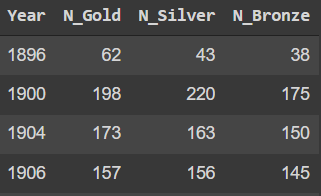

In [ ]:
pd.crosstab(athlete_df["Year"], athlete_df["Medal"])

Medal,Bronze,Gold,Silver
Year,,,
1896,38,62,43
1900,175,198,220
1904,150,173,163
1906,145,157,156
1908,256,294,281
1912,300,326,315
1920,367,493,448
1924,311,332,319
1928,281,275,267


# <font color='red'>**You are Geek!**</fond>
### Provide all your answers with plots

### Find the number of winners with the gold medal in each city?

City
London                    1215
Athina                     883
Los Angeles                726
Beijing                    671
Rio de Janeiro             665
Sydney                     663
Atlanta                    608
Barcelona                  559
Seoul                      520
Antwerpen                  493
Paris                      475
Moskva                     457
Montreal                   438
Munich                     404
Mexico City                359
Tokyo                      347
Stockholm                  338
Berlin                     312
Roma                       309
Helsinki                   306
Melbourne                  290
Amsterdam                  245
Sochi                      202
Torino                     176
Vancouver                  174
St. Louis                  173
Salt Lake City             162
Nagano                     145
Innsbruck                  131
Lillehammer                110
Lake Placid                104
Albertville                104
Cal

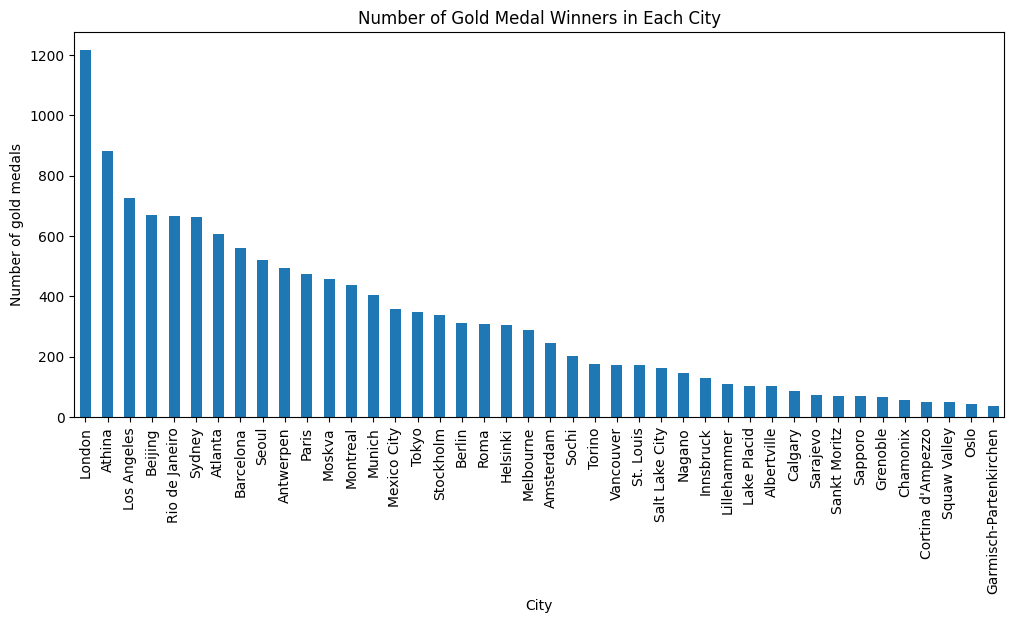

In [ ]:
gold = athlete_df[athlete_df["Medal"] == "Gold"]
gold_city = gold["City"].value_counts()
print(gold_city)

gold_city.plot(kind="bar", figsize=(12, 5))
plt.title("Number of Gold Medal Winners in Each City")
plt.xlabel("City")
plt.ylabel("Number of gold medals")
plt.show()

### Find the total missing data for each year?

Year
1896     1065
1900     5676
1904     3331
1906     5022
1908     8057
1912    10018
1920    11175
1924    15194
1928    14124
1932     6308
1936    18433
1948    20008
1952    22943
1956    13531
1960    10407
1964     9710
1968     9663
1972    11331
1976    10819
1980     8706
1984    11307
1988    14802
1992    20759
1994     3207
1996    15638
1998     3337
2000    12067
2002     3707
2004    11515
2006     3878
2008    11866
2010     3908
2012    11507
2014     4532
2016    12064
dtype: int64


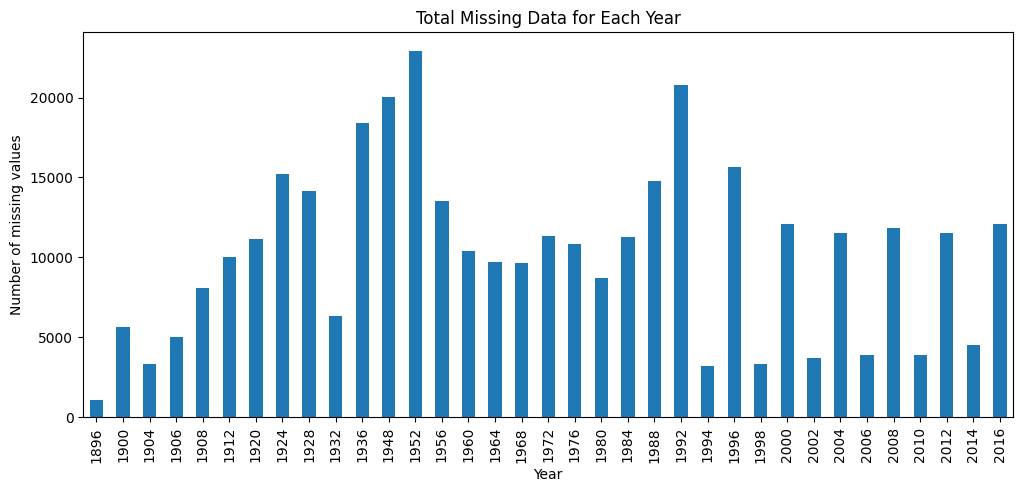

In [ ]:
missing_per_year = athlete_df.isnull().sum(axis=1).groupby(athlete_df["Year"]).sum()
print(missing_per_year)

missing_per_year.plot(kind="bar", figsize=(12, 5))
plt.title("Total Missing Data for Each Year")
plt.xlabel("Year")
plt.ylabel("Number of missing values")
plt.show()

# <font color='red'>**I dare you to solve this :)**</fond>
### Dont use for loops, and provide all your answers with plots.

### Has the number of athletes changed over time for Summer and Winter?

Season   Summer  Winter
Year                   
1896      176.0     NaN
1900     1224.0     NaN
1904      650.0     NaN
1906      841.0     NaN
1908     2024.0     NaN
1912     2409.0     NaN
1920     2676.0     NaN
1924     3256.0   313.0
1928     3247.0   461.0
1932     1922.0   252.0
1936     4484.0   668.0
1948     4402.0   668.0
1952     4932.0   694.0
1956     3347.0   821.0
1960     5352.0   665.0
1964     5137.0  1094.0
1968     5558.0  1160.0
1972     7114.0  1008.0
1976     6073.0  1128.0
1980     5259.0  1071.0
1984     6798.0  1273.0
1988     8454.0  1425.0
1992     9386.0  1801.0
1994        NaN  1738.0
1996    10339.0     NaN
1998        NaN  2179.0
2000    10647.0     NaN
2002        NaN  2399.0
2004    10557.0     NaN
2006        NaN  2494.0
2008    10899.0     NaN
2010        NaN  2536.0
2012    10517.0     NaN
2014        NaN  2745.0
2016    11179.0     NaN


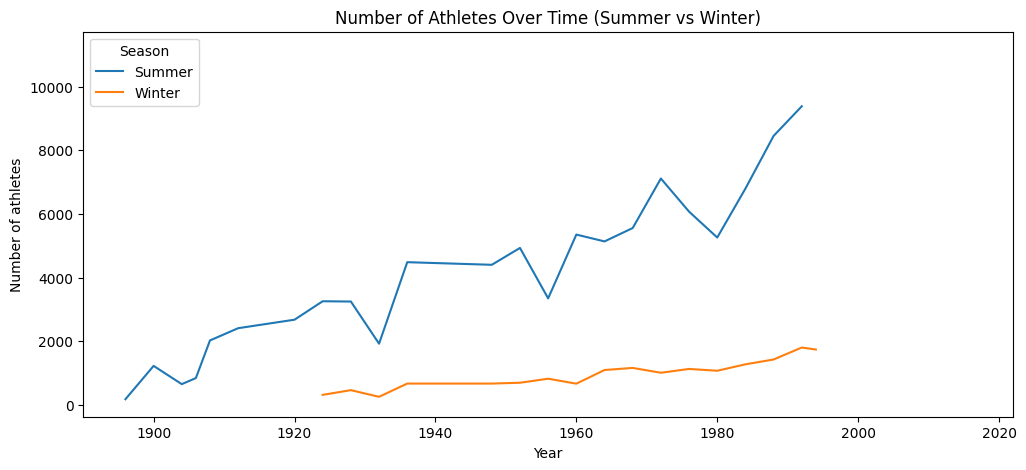

In [ ]:
athletes = athlete_df.groupby(["Year", "Season"])["ID"].nunique().unstack()
print(athletes)

athletes.plot(figsize=(12, 5))
plt.title("Number of Athletes Over Time (Summer vs Winter)")
plt.xlabel("Year")
plt.ylabel("Number of athletes")
plt.show()